In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2M

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from collections import Counter
from imblearn.combine import SMOTEENN


In [2]:

TRAIN_GROUNDTRUTH_PATH = "data/train/ISIC_2019_Training_GroundTruth.csv"
TEST_GROUNDTRUTH_PATH = "ham10000/HAM10000_Test_GroundTruth_Updated.csv"
TEST2_GROUNDTRUTH_PATH = "data/test/ISIC_2019_Test_GroundTruth.csv"


TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"  
TEST_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"  
TEST2_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input"  
IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20 

LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [3]:
def read_ds(gnd_path):
    """Read a dataset from CSV file and assign labels correspondingly."""
    gnd = pd.read_csv(gnd_path)
    gnd['y'] = gnd[LABELS].idxmax(axis=1)

    return gnd

def get_image_paths_and_labels(groundtruth, image_dir):
    """Generate image paths and corresponding labels from a groundtruth DataFrame."""
    image_paths = [
        os.path.join(image_dir, row['image'] + '.jpg') 
        for _, row in groundtruth.iterrows()
    ]
    labels = [
        LABELS.index(row['y']) 
        for _, row in groundtruth.iterrows()
    ]
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH) 
test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH) 
test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)
train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

FileNotFoundError: [Errno 2] No such file or directory: 'data/train/ISIC_2019_Training_GroundTruth.csv'

In [5]:
# ros = RandomUnderSampler(sampling_strategy='auto')
# train_paths_resampled, train_labels_resampled = ros.fit_resample(np.array(train_paths).reshape(-1, 1), train_labels)
# train_paths_resampled = train_paths_resampled.flatten()
# print(f"Before downsampling: {Counter(train_labels)}")

# train_paths, train_labels = train_paths_resampled, train_labels_resampled

# print(f"After downsampling: {Counter(train_labels_resampled)}")

In [6]:
# print(f"Before resampling: {Counter(train_labels)}")

# indices = np.arange(len(train_paths)).reshape(-1, 1)

# smt = SMOTETomek(random_state=42)
# indices_resampled, train_labels_resampled = smt.fit_resample(indices, train_labels)

# train_paths_resampled = [train_paths[i] for i in indices_resampled.flatten()]
# train_labels = train_labels_resampled
# train_paths = train_paths_resampled
# print(f"After resampling: {Counter(train_labels_resampled)}")

In [7]:
from imblearn.combine import SMOTEENN
from collections import Counter
import numpy as np

# Check class distribution before resampling
print(f"Before resampling: {Counter(train_labels)}")

# Convert paths to numeric indices (temporarily)
indices = np.arange(len(train_paths)).reshape(-1, 1)

# Apply SMOTEENN on labels (not paths)
smote_enn = SMOTEENN(random_state=42)
indices_resampled, train_labels_resampled = smote_enn.fit_resample(indices, train_labels)

# Retrieve the actual file paths using the resampled indices
train_paths_resampled = [train_paths[i] for i in indices_resampled.flatten()]
train_labels = train_labels_resampled
train_paths = train_paths_resampled

# Check class distribution after resampling
print(f"After resampling: {Counter(train_labels_resampled)}")


Before resampling: Counter({1: 12875, 0: 4522, 2: 3323, 4: 2624, 3: 867, 7: 628, 6: 253, 5: 239})
After resampling: Counter({4: 1742, 0: 1582, 2: 1523, 3: 1337, 1: 955, 6: 890, 5: 739, 7: 569})


In [8]:
# Image preprocessing function
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

# Data Augmentation

In [9]:
import tensorflow as tf

def rotate_image(image, degrees):
    """Applies rotation without TFA using image transformation matrices."""
    radians = degrees * (3.14159265 / 180.0)
    cosine = tf.cos(radians)
    sine = tf.sin(radians)

    # Affine transformation matrix for rotation
    transform = [cosine, -sine, 0,  
                 sine, cosine, 0,  
                 0, 0]  

    # Apply transformation
    image = tf.raw_ops.ImageProjectiveTransformV2(
        images=tf.expand_dims(image, 0),  # Add batch dimension
        transforms=[transform], 
        output_shape=[IMG_SIZE[0], IMG_SIZE[1]],
        interpolation="BILINEAR"
    )
    return tf.squeeze(image)  # Remove batch dimension

def preprocess_and_augment(file_path, label):
    image = tf.io.read_file(file_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])

    # EfficientNet preprocessing
    image = tf.keras.applications.efficientnet.preprocess_input(image)

    # Data Augmentation
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.image.random_hue(image, max_delta=0.1)

    # Apply rotation (-20 to +20 degrees)
    angle = tf.random.uniform([], minval=-20, maxval=20, dtype=tf.float32)
    image = rotate_image(image, angle)

    return image, label


In [10]:
shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .cache("train.ds")\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

2025-03-12 10:20:15.304346: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-03-12 10:20:15.304388: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-03-12 10:20:15.304393: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1741767615.305706 1878389 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1741767615.306186 1878389 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# Model

In [11]:
base_model = EfficientNetV2M(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(1024, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(len(LABELS), activation="softmax")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.SparseCategoricalAccuracy(name="sparse_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy")
    ]
)

In [12]:
model_path = "EfficientNetV2M_balanced_baserun.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

# if os.path.exists(model_path):
#     model = tf.keras.models.load_model(model_path)

early_stop = tf.keras.callbacks.EarlyStopping(
    restore_best_weights=True,
    monitor="val_loss",
    patience=5,  
)

lr_schedule = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)


In [13]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,474,428 (207.80 MB)

 Trainable params: 1,321,992 (5.04 MB)

 Non-trainable params: 53,152,436 (202.76 MB)

In [14]:
# Imbalance in the dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# Training & Saving the Model

In [15]:
# Train the model
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop, lr_schedule]
)

Epoch 1/20


2025-03-12 10:20:41.707890: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


292/292 ━━━━━━━━━━━━━━━━━━━━ 782s 3s/step - accuracy: 0.2277 - loss: 3.0007 - sparse_accuracy: 0.2277 - top3_accuracy: 0.4919 - val_accuracy: 0.6744 - val_loss: 1.0653 - val_sparse_accuracy: 0.6744 - val_top3_accuracy: 0.8415 - learning_rate: 5.0000e-04
Epoch 2/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 717s 2s/step - accuracy: 0.5304 - loss: 1.5818 - sparse_accuracy: 0.5304 - top3_accuracy: 0.7457 - val_accuracy: 0.6937 - val_loss: 0.9773 - val_sparse_accuracy: 0.6937 - val_top3_accuracy: 0.8788 - learning_rate: 5.0000e-04
Epoch 3/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 723s 2s/step - accuracy: 0.6082 - loss: 1.2747 - sparse_accuracy: 0.6082 - top3_accuracy: 0.8072 - val_accuracy: 0.7043 - val_loss: 0.9014 - val_sparse_accuracy: 0.7043 - val_top3_accuracy: 0.8974 - learning_rate: 5.0000e-04
Epoch 4/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 720s 2s/step - accuracy: 0.6422 - loss: 1.1226 - sparse_accuracy: 0.6422 - top3_accuracy: 0.8437 - val_accuracy: 0.7063 - val_loss: 0.9036 - val_sparse_accuracy: 0.7063 - val_t

In [16]:
model = models.load_model('EfficientNetV2M_balanced_baserun.keras')

In [17]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,796,422 (212.85 MB)

 Trainable params: 1,321,992 (5.04 MB)

 Non-trainable params: 53,152,436 (202.76 MB)

 Optimizer params: 1,321,994 (5.04 MB)

In [18]:
for i in model.layers:
    if i.name == 'efficientnetv2-m':
        for layer in i.layers[-100:]:
            layer.trainable = True
    if i.name == 'batch_normalization':
        print("batch found")
        i.trainable = False

batch found


In [19]:
model.compile(
optimizer=tf.keras.optimizers.Adam(1e-5), 
loss="sparse_categorical_crossentropy", 
metrics=[
        "accuracy",
        tf.keras.metrics.SparseCategoricalAccuracy(name="sparse_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy")
    ]
)

In [20]:
model_path = "EfficientNetV2M_balanced_finetuning.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

In [21]:
BATCH_SIZE = 16

shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .cache("train.ds")\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

In [22]:
history_finetuning = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop, lr_schedule]
)

Epoch 1/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 1489s 2s/step - accuracy: 0.6538 - loss: 0.9671 - sparse_accuracy: 0.6538 - top3_accuracy: 0.9134 - val_accuracy: 0.7107 - val_loss: 0.8493 - val_sparse_accuracy: 0.7107 - val_top3_accuracy: 0.9116 - learning_rate: 1.0000e-05
Epoch 2/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 1417s 2s/step - accuracy: 0.6709 - loss: 0.8819 - sparse_accuracy: 0.6709 - top3_accuracy: 0.9198 - val_accuracy: 0.7232 - val_loss: 0.8105 - val_sparse_accuracy: 0.7232 - val_top3_accuracy: 0.9202 - learning_rate: 1.0000e-05
Epoch 3/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 1455s 2s/step - accuracy: 0.6941 - loss: 0.8001 - sparse_accuracy: 0.6941 - top3_accuracy: 0.9343 - val_accuracy: 0.7433 - val_loss: 0.7596 - val_sparse_accuracy: 0.7433 - val_top3_accuracy: 0.9344 - learning_rate: 1.0000e-05
Epoch 4/20
584/584 ━━━━━━━━━━━━━━━━━━━━ 1601s 3s/step - accuracy: 0.7041 - loss: 0.7587 - sparse_accuracy: 0.7041 - top3_accuracy: 0.9416 - val_accuracy: 0.7611 - val_loss: 0.6940 - val_sparse_accuracy:

### HAM10000

In [ ]:
# HAM10000
result = model.evaluate(test_dataset)


626/626 ━━━━━━━━━━━━━━━━━━━━ 232s 369ms/step - accuracy: 0.5008 - loss: 1.3804 - sparse_accuracy: 0.5008 - top3_accuracy: 0.8872


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [46]:
print(result)

[1.0808604955673218, 0.6853719353675842, 0.6853719353675842, 0.8903644680976868]


In [23]:
y_true = np.concatenate([y for _, y in test_dataset], axis=0)
y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)

2025-03-13 00:45:34.183486: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


626/626 ━━━━━━━━━━━━━━━━━━━━ 473s 735ms/step


In [29]:
score_report = classification_report(y_true, y_pred, target_names=[LABELS[i] for i in range(8)], zero_division=0)
print(score_report)

              precision    recall  f1-score   support

         MEL       0.50      0.56      0.52      1113
          NV       0.92      0.92      0.92      6705
         BCC       0.63      0.81      0.71       514
          AK       0.54      0.15      0.24       327
         BKL       0.69      0.58      0.63      1099
          DF       0.65      0.50      0.56       115
        VASC       0.85      0.79      0.82       142
         SCC       0.00      0.00      0.00         0

    accuracy                           0.81     10015
   macro avg       0.60      0.54      0.55     10015
weighted avg       0.82      0.81      0.81     10015



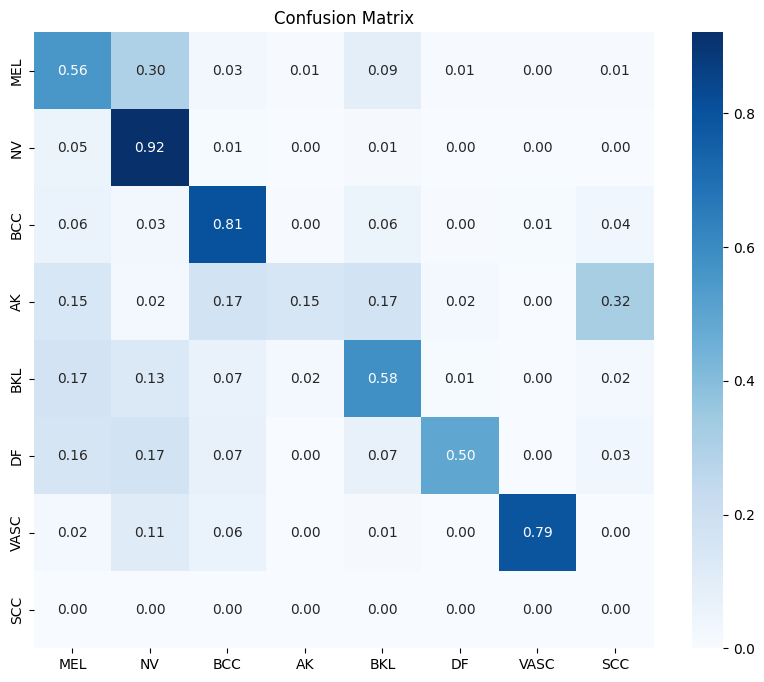

In [25]:
conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

### ISIC 2019

In [37]:
# ISIC 2019
test_loss, test_accuracy = model.evaluate(test_dataset_2)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

515/515 ━━━━━━━━━━━━━━━━━━━━ 100s 193ms/step - accuracy: 0.4936 - loss: 1.6373 - sparse_accuracy: 0.4936 - top3_accuracy: 0.7620


ValueError: too many values to unpack (expected 2)

In [26]:
y2_true = np.concatenate([y for _, y in test_dataset_2], axis=0)
y2_pred = model.predict(test_dataset_2)
y2_pred = np.argmax(y2_pred, axis=1)

2025-03-13 00:53:39.449229: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


515/515 ━━━━━━━━━━━━━━━━━━━━ 329s 638ms/step


In [27]:
score_report = classification_report(y2_true, 
                                     y2_pred, 
                                     target_names=[LABELS[i] for i in range(8)])
print(score_report)

              precision    recall  f1-score   support

         MEL       0.63      0.32      0.42      3374
          NV       0.65      0.82      0.73      2495
         BCC       0.37      0.72      0.49       975
          AK       0.15      0.08      0.10       374
         BKL       0.34      0.32      0.33       660
          DF       0.20      0.30      0.24        91
        VASC       0.39      0.32      0.35       104
         SCC       0.15      0.36      0.21       165

    accuracy                           0.51      8238
   macro avg       0.36      0.41      0.36      8238
weighted avg       0.54      0.51      0.49      8238



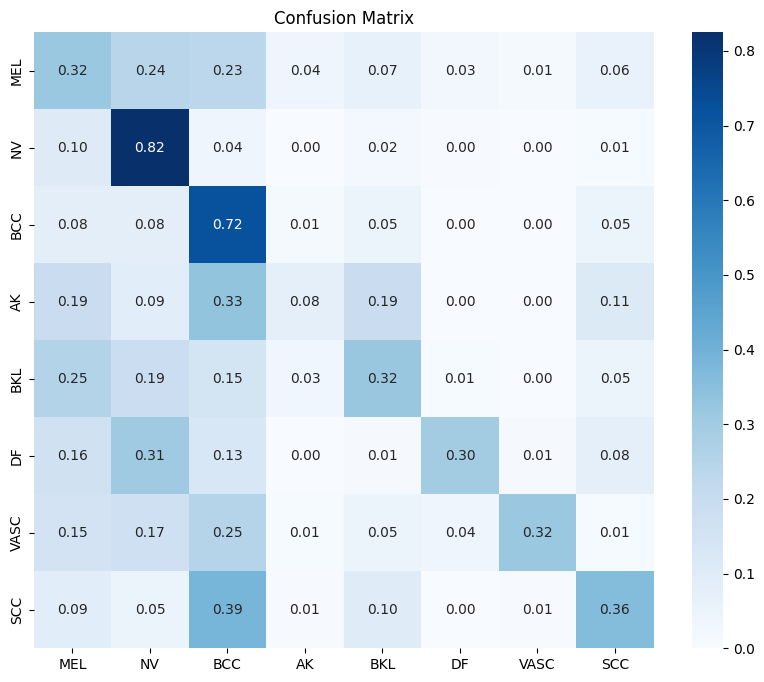

In [28]:
conf_matrix = confusion_matrix(y2_true, 
                               y2_pred, 
                               normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

In [32]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import pandas as pd

# Define class labels (update according to your dataset)
LABELS = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

# Load a trained model (update with your model path)
MODEL_PATH = "your_model.h5"
model = tf.keras.models.load_model(MODEL_PATH)

# Function to preprocess image
def preprocess_image(img_path, img_size=(224, 224)):  # Adjust size if needed
    img = image.load_img(img_path, target_size=img_size)
    img_array = image.img_to_array(img) / 255.0  # Normalize to [0,1]
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    return img_array

# Group the images by their labels
def group_images_by_label(paths, labels):
    grouped = {label: [] for label in LABELS}
    for path, label in zip(paths, labels):
        grouped[LABELS[label]].append(path)
    return grouped

# Get grouped images for each dataset
grouped_test_1 = group_images_by_label(test_paths, test_labels)
grouped_test_2 = group_images_by_label(test_paths_2, test_labels_2)

# Select one image per label from each dataset
selected_images_1 = {label: random.choice(paths) for label, paths in grouped_test_1.items()}
selected_images_2 = {label: random.choice(paths) for label, paths in grouped_test_2.items()}

# Prepare a figure for displaying images
fig, axes = plt.subplots(2, len(LABELS), figsize=(20, 10))

# Make predictions and display images
for idx, label in enumerate(LABELS):
    # Get the selected images
    img_1_path = selected_images_1[label]
    img_2_path = selected_images_2[label]

    # Preprocess and predict for each image
    img_1 = preprocess_image(img_1_path)
    img_2 = preprocess_image(img_2_path)
    
    pred_1 = model.predict(img_1)
    pred_2 = model.predict(img_2)
    
    # Get predicted labels
    label_1 = LABELS[np.argmax(pred_1)]
    label_2 = LABELS[np.argmax(pred_2)]

    # Plot the images with predictions
    axes[0, idx].imshow(image.load_img(img_1_path))
    axes[0, idx].set_title(f"Dataset 1\nPred: {label_1}")
    axes[0, idx].axis('off')
    
    axes[1, idx].imshow(image.load_img(img_2_path))
    axes[1, idx].set_title(f"Dataset 2\nPred: {label_2}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] Unable to open file (unable to open file: name = 'your_model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
memory_info = tf.config.experimental.get_memory_info('GPU:0')

print("Memory Usage (Bytes):", memory_info)

In [1]:
import tensorflow as tf
import json

# Provided training history data
training_data = {
    'accuracy': [0.6538, 0.6709, 0.6941, 0.7041, 0.7185, 0.7300, 0.7473, 0.7582, 0.7737, 0.7840, 0.8022, 0.8076, 0.8268, 0.8417, 0.8470, 0.8608, 0.8710],
    'loss': [0.9671, 0.8819, 0.8001, 0.7587, 0.7109, 0.6746, 0.6357, 0.6043, 0.5629, 0.5299, 0.4857, 0.4631, 0.4168, 0.3770, 0.3581, 0.3319, 0.3063],
    'sparse_accuracy': [0.6538, 0.6709, 0.6941, 0.7041, 0.7185, 0.7300, 0.7473, 0.7582, 0.7737, 0.7840, 0.8022, 0.8076, 0.8268, 0.8417, 0.8470, 0.8608, 0.8710],
    'top3_accuracy': [0.9134, 0.9198, 0.9343, 0.9416, 0.9507, 0.9545, 0.9611, 0.9668, 0.9706, 0.9746, 0.9779, 0.9806, 0.9849, 0.9872, 0.9876, 0.9904, 0.9928],
    'val_accuracy': [0.7107, 0.7232, 0.7433, 0.7611, 0.7762, 0.7809, 0.7871, 0.7898, 0.7900, 0.7929, 0.8008, 0.8054, 0.8079, 0.8122, 0.8117, 0.8169, 0.8251],
    'val_loss': [0.8493, 0.8105, 0.7596, 0.6940, 0.6625, 0.6422, 0.6269, 0.6117, 0.6081, 0.6076, 0.5938, 0.5887, 0.6010, 0.5945, 0.6013, 0.6048, 0.6031],
    'val_sparse_accuracy': [0.7107, 0.7232, 0.7433, 0.7611, 0.7762, 0.7809, 0.7871, 0.7898, 0.7900, 0.7929, 0.8008, 0.8054, 0.8079, 0.8122, 0.8117, 0.8169, 0.8251],
    'val_top3_accuracy': [0.9116, 0.9202, 0.9344, 0.9447, 0.9491, 0.9524, 0.9550, 0.9578, 0.9586, 0.9590, 0.9625, 0.9653, 0.9643, 0.9658, 0.9657, 0.9672, 0.9693],
    'learning_rate': [1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 1e-05, 5e-06, 5e-06]
}

# Create a dummy History object and assign the provided data.
history = tf.keras.callbacks.History()
history.epoch = list(range(1, len(training_data['accuracy']) + 1))  # Create epoch numbers
history.history = training_data

# Convert the history.history dictionary to a JSON string
json_string = json.dumps(history.history, indent=4)  # indent for pretty printing

# Print the JSON string
print(json_string)

{
    "accuracy": [
        0.6538,
        0.6709,
        0.6941,
        0.7041,
        0.7185,
        0.73,
        0.7473,
        0.7582,
        0.7737,
        0.784,
        0.8022,
        0.8076,
        0.8268,
        0.8417,
        0.847,
        0.8608,
        0.871
    ],
    "loss": [
        0.9671,
        0.8819,
        0.8001,
        0.7587,
        0.7109,
        0.6746,
        0.6357,
        0.6043,
        0.5629,
        0.5299,
        0.4857,
        0.4631,
        0.4168,
        0.377,
        0.3581,
        0.3319,
        0.3063
    ],
    "sparse_accuracy": [
        0.6538,
        0.6709,
        0.6941,
        0.7041,
        0.7185,
        0.73,
        0.7473,
        0.7582,
        0.7737,
        0.784,
        0.8022,
        0.8076,
        0.8268,
        0.8417,
        0.847,
        0.8608,
        0.871
    ],
    "top3_accuracy": [
        0.9134,
        0.9198,
        0.9343,
        0.9416,
        0.9507,
        0.9545,